# EN-3160 Image Processing and Machine Vision
## Assignment 02

* **Name:** Wijethilaka J.S.
* **Index Number:** 230730T
* **Github Repository Link:** https://github.com/Januka-Sanujaya/EN3160_Assignment_03

## Question 1: Neural Network on CIFAR-10

Using device: cuda


100.0%


Epoch [01/10] Loss: 1.7932 | Train Accuracy: 37.33% | Test Accuracy: 40.24%
Epoch [02/10] Loss: 1.6643 | Train Accuracy: 42.31% | Test Accuracy: 42.45%
Epoch [03/10] Loss: 1.6023 | Train Accuracy: 44.50% | Test Accuracy: 44.49%
Epoch [04/10] Loss: 1.5495 | Train Accuracy: 46.58% | Test Accuracy: 44.45%
Epoch [05/10] Loss: 1.5067 | Train Accuracy: 48.11% | Test Accuracy: 46.31%
Epoch [06/10] Loss: 1.4695 | Train Accuracy: 49.24% | Test Accuracy: 46.75%
Epoch [07/10] Loss: 1.4326 | Train Accuracy: 50.60% | Test Accuracy: 47.34%
Epoch [08/10] Loss: 1.3990 | Train Accuracy: 51.82% | Test Accuracy: 47.02%
Epoch [09/10] Loss: 1.3672 | Train Accuracy: 52.97% | Test Accuracy: 47.72%
Epoch [10/10] Loss: 1.3365 | Train Accuracy: 53.86% | Test Accuracy: 47.48%

Total training time: 92.49 seconds


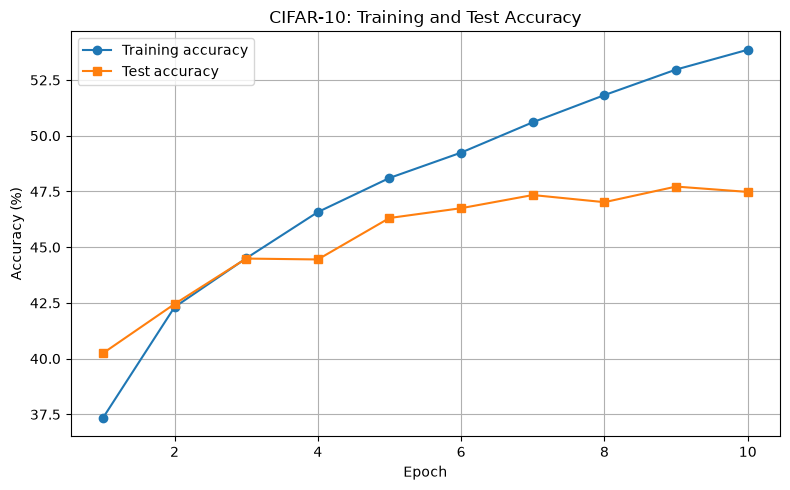

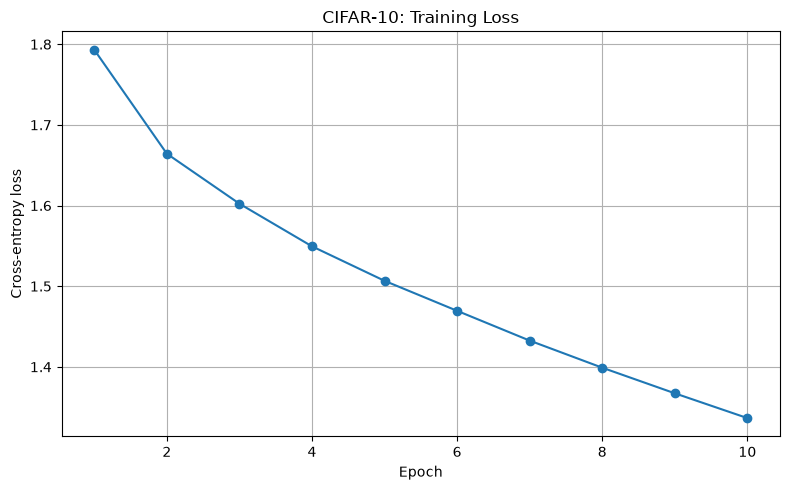

In [3]:
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

# Reproducibility
torch.manual_seed(42)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Load CIFAR-10
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

# 2. Network dimensions
input_size = 3 * 32 * 32
hidden_size = 100
output_size = 10

# Xavier initialization
W1 = (
    torch.randn(input_size, hidden_size, device=device)
    * (2.0 / (input_size + hidden_size)) ** 0.5
).requires_grad_()

b1 = torch.zeros(hidden_size, device=device, requires_grad=True)

W2 = (
    torch.randn(hidden_size, output_size, device=device)
    * (2.0 / (hidden_size + output_size)) ** 0.5
).requires_grad_()

b2 = torch.zeros(output_size, device=device, requires_grad=True)

parameters = [W1, b1, W2, b2]

learning_rate = 0.1
num_epochs = 10

train_accuracies = []
test_accuracies = []
train_losses = []

# 3. Forward pass
def forward(X):
    hidden = torch.sigmoid(X @ W1 + b1)
    logits = hidden @ W2 + b2
    return logits

# 4. Accuracy evaluation
def evaluate(loader):
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            X = images.reshape(images.size(0), -1)
            logits = forward(X)
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total

# 5. Training loop with manual parameter updates
start_time = time.time()

for epoch in range(num_epochs):
    running_loss = 0.0
    total = 0
    correct = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        X = images.reshape(images.size(0), -1)

        # Forward propagation
        logits = forward(X)

        # Cross-entropy loss
        loss = F.cross_entropy(logits, labels)

        # Compute gradients using automatic differentiation
        for parameter in parameters:
            parameter.grad = None

        loss.backward()

        # Manually update parameters using gradient descent
        with torch.no_grad():
            for parameter in parameters:
                parameter -= learning_rate * parameter.grad

        running_loss += loss.item() * labels.size(0)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    train_accuracy = 100.0 * correct / total
    test_accuracy = evaluate(testloader)

    train_losses.append(epoch_loss)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)

    print(
        f"Epoch [{epoch + 1:02d}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

elapsed_time = time.time() - start_time
print(f"\nTotal training time: {elapsed_time:.2f} seconds")

# 6. Plot results
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, marker="o", label="Training accuracy")
plt.plot(epochs, test_accuracies, marker="s", label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CIFAR-10: Training and Test Accuracy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CIFAR-10: Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()


## Results and Observations

The neural network was trained on the CIFAR-10 dataset for 10 epochs using a hidden layer containing 100 neurons with sigmoid activation and cross-entropy loss. Training was performed using the NVIDIA RTX 5070 Ti Laptop GPU.

### Training Results

| Epoch | Training Loss | Training Accuracy (%) | Test Accuracy (%) |
|---:|---:|---:|---:|
| 1 | 1.7932 | 37.33 | 40.24 |
| 2 | 1.6643 | 42.31 | 42.45 |
| 3 | 1.6023 | 44.50 | 44.49 |
| 4 | 1.5495 | 46.58 | 44.45 |
| 5 | 1.5067 | 48.11 | 46.31 |
| 6 | 1.4695 | 49.24 | 46.75 |
| 7 | 1.4326 | 50.60 | 47.34 |
| 8 | 1.3990 | 51.82 | 47.02 |
| 9 | 1.3672 | 52.97 | 47.72 |
| 10 | 1.3365 | 53.86 | 47.48 |

### Final Performance

- **Final training accuracy:** 53.86%
- **Final test accuracy:** 47.48%
- **Final training loss:** 1.3365
- **Highest test accuracy:** 47.72% (Epoch 9)

### Observations

1. **Loss reduction:** The training loss decreased consistently from 1.7932 to 1.3365 over the 10 epochs, indicating that the model progressively improved its predictions on the training data.

2. **Training accuracy:** Training accuracy increased from 37.33% in the first epoch to 53.86% in the final epoch, demonstrating that the network learned useful patterns from the CIFAR-10 images.

3. **Test accuracy:** Test accuracy generally improved during training, reaching a maximum of 47.72% in Epoch 9 before decreasing slightly to 47.48% in Epoch 10.

4. **Generalization:** The final training accuracy was 6.38 percentage points higher than the final test accuracy. This indicates a difference between training and test performance, although these results alone do not establish severe overfitting.

5. **Model limitations:** The fully connected network flattens each image into a one-dimensional vector and therefore does not explicitly exploit the spatial relationships between neighbouring pixels. This limits its ability to learn complex image features compared with convolutional neural networks.
